# Experiment 3: Dimensionality reduction (truncated SVD)

Apply truncated SVD to raw-count and TF-IDF vectors and check how retrieval quality changes. Data: first 50 articles from each BBC category (250 documents).

## 1. Load data

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

DATA_DIR = "../data/bbc"
CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]
N_PER_CAT = 50
K_VALUES = [2, 5, 10, 20, 50, 100, 200]
SEED = 42

texts, labels = [], []
for cat in CATEGORIES:
    files = sorted(os.listdir(f"{DATA_DIR}/{cat}"))[:N_PER_CAT]
    for f in files:
        with open(f"{DATA_DIR}/{cat}/{f}", encoding="latin-1") as file:
            texts.append(file.read())
        labels.append(cat)
labels = np.array(labels)

print(len(texts), "documents")
print(pd.Series(labels).value_counts())

250 documents
business         50
entertainment    50
politics         50
sport            50
tech             50
Name: count, dtype: int64


## 2. Build the vectors

In [6]:
settings = dict(stop_words="english", token_pattern=r"[a-zA-Z]{2,}", min_df=2)

X_count = CountVectorizer(**settings).fit_transform(texts)
X_tfidf = TfidfVectorizer(**settings).fit_transform(texts)

print("raw counts:", X_count.shape)
print("tf-idf:", X_tfidf.shape)

raw counts: (250, 4400)
tf-idf: (250, 4400)


## 3. Evaluation
Every document is used as a query once. The other 249 documents are ranked by cosine similarity, and a result counts as relevant if it is in the same category as the query. We report P@10 and MAP.

In [12]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity


def evaluate(vectors, labels):
    # every document is used as a query once, the other documents are ranked by cosine similarity
    # a result is relevant if it has the same category as the query
    labels = np.array(labels)
    sim = cosine_similarity(vectors)
    np.fill_diagonal(sim, -np.inf)
    order = np.argsort(-sim, axis=1)[:, :-1]
    relevant = labels[order] == labels[:, None]

    p10 = relevant[:, :10].mean(axis=1).mean()

    ranks = np.arange(1, relevant.shape[1] + 1)
    precision_at_rank = np.cumsum(relevant, axis=1) / ranks
    ap = (precision_at_rank * relevant).sum(axis=1) / relevant.sum(axis=1)

    first_hit = relevant.argmax(axis=1) + 1
    mrr = (1 / first_hit).mean()

    return {"P@10": p10, "MAP": ap.mean(), "MRR": mrr}

## 4. Baseline (no SVD)

In [14]:
for name, X in [("raw counts", X_count), ("tf-idf", X_tfidf)]:
    scores = evaluate(X, labels)
    print(name, scores)

raw counts {'P@10': np.float64(0.7855999999999999), 'MAP': np.float64(0.5847825735197617), 'MRR': np.float64(0.9399658376711009)}
tf-idf {'P@10': np.float64(0.8224), 'MAP': np.float64(0.6440907996605789), 'MRR': np.float64(0.945563492063492)}


## 5. Truncated SVD

In [15]:
results = []
for name, X in [("raw counts", X_count), ("tf-idf", X_tfidf)]:
    for k in K_VALUES:
        svd = TruncatedSVD(n_components=k, random_state=SEED)
        reduced = svd.fit_transform(X)
        scores = evaluate(reduced, labels)
        results.append([name, k, svd.explained_variance_ratio_.sum(), scores["P@10"], scores["MAP"], scores["MRR"]])

results = pd.DataFrame(results, columns=["vectors", "k", "explained_var", "P@10", "MAP", "MRR"])
results.round(3)

,vectors,k,explained_var,P@10,MAP,MRR
0,raw counts,2,0.057,0.362,0.369,0.512
1,raw counts,5,0.121,0.794,0.671,0.883
2,raw counts,10,0.195,0.832,0.704,0.931
3,raw counts,20,0.308,0.844,0.660,0.932
4,raw counts,50,0.529,0.775,0.577,0.925
5,raw counts,100,0.742,0.739,0.546,0.912
6,raw counts,200,0.954,0.756,0.563,0.924
7,tf-idf,2,0.022,0.537,0.523,0.672
8,tf-idf,5,0.067,0.818,0.743,0.896
9,tf-idf,10,0.123,0.928,0.783,0.960


## 6. Plot

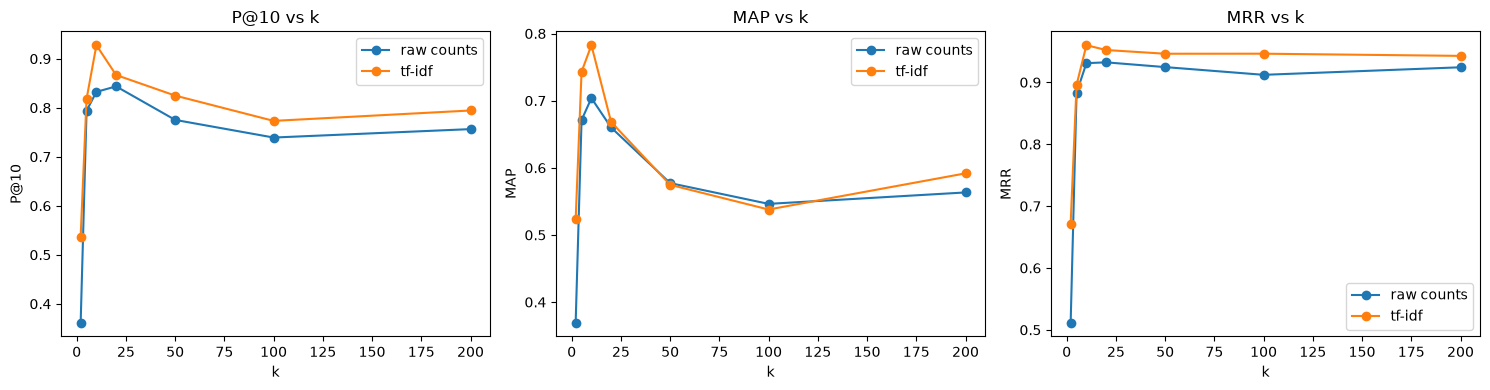

In [20]:
  fig, axes = plt.subplots(1, 3, figsize=(15, 4))
  for ax, metric in zip(axes, ["P@10", "MAP", "MRR"]):
      for name in ["raw counts", "tf-idf"]:
          sub = results[results["vectors"] == name]
          ax.plot(sub["k"], sub[metric], marker="o", label=name)
      ax.set_xlabel("k")
      ax.set_ylabel(metric)
      ax.set_title(metric + " vs k")
      ax.legend()
  plt.tight_layout()
  plt.savefig("../results/exp3_plot.png")
  plt.show()

## 7. Save results

In [21]:
results.to_csv("../results/exp3_results.csv", index=False)

## 8. Observations

Truncated SVD gave the best retrieval at small k: TF-IDF at k = 10 reached P@10 = 0.928, MAP = 0.783 and MRR = 0.960, compared with 0.822 and 0.644 (P@10 and MAP) without SVD. For k ≥ 50, MAP fell below the baseline and P@10 was about equal to it, and k = 2 was too small to work. TF-IDF beat raw counts on P@10 and MRR at every k, but on MAP only at small k.